# Exploratory Data Analysis — Gujarat Company Master Data
**Course:** IT462 · Exploratory Data Analysis · Autumn Semester (AY 2026-27) · Final Project
**Dataset:** `data/raw/EDA_Project_Dataset.csv` — 222,915 companies registered with the Registrar of Companies (MCA master extract), 1880–2026

> **Academic integrity & AI acknowledgement (per course policy):** This notebook was prepared with AI assistance as an exploratory/demo scaffold; every number and figure shown is **computed live from the actual dataset** in the cells below — nothing is hard-coded. Reviewers can re-run the notebook end-to-end to reproduce all results.

**Companion deliverables** (built from the same pipeline, identical numbers):
`src/` modules · `website/app.py` (Streamlit dashboard) · `reports/analysis_report.md` · `reports/eda_presentation.pptx` · `tests/`

**How to run:** `jupyter lab notebooks/EDA_Demo.ipynb` from the project root — the notebook is executable top-to-bottom (Kernel → Restart & Run All).

## Learning outcomes exercised (IT462)
| Course outcome | Where in this notebook |
|---|---|
| **CO1** Import, manipulate, clean, visualize, export data in Python | §1–§4, all figures, cleaned CSV export |
| **CO2** Systematic EDA of different types of data | §1 (structure & scales) → §6 (univariate) → §8 (bivariate) → §9 (correlation/fit) → §10 (time series) |
| **CO3** Research methods: analysis, interpretation, valid conclusions | §3 (missingness mechanisms), §11 (findings), §12 (limitations) |

**Concepts mapped to the syllabus:** measurement scales · data import & cleaning · duplicate detection · invalid entries · type conversion · missing-data mechanisms (MCAR/MAR/MNAR) · five-number summary, IQR, MAD, CV · histogram, boxplot, bar chart, scatter · crosstab & chi-square · Pearson & Spearman correlation · OLS fit & R² · IQR/z-score outliers · trend & seasonality · concentration (Lorenz/Gini)

In [1]:
from pathlib import Path
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

# --- make the reusable src/ package importable (notebook lives in notebooks/) ---
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import data_loader as dl
from src import data_cleaning as dc
from src import statistical_analysis as sa
from src import visualization as vz
from src import insights as ins

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
vz.set_plot_style()
print("Project root:", ROOT)

Project root: /home/z/my-project/download/EDA_Project


## 1 · Data import & first inspection (CO1)
The raw file is treated as **read-only**: `load_raw()` never mutates it. We first measure its structure — 16 columns, mixed types — and map every field to its **measurement scale** (nominal / ordinal / interval / ratio), the first checkpoint of the course's measurement-scales module.

In [2]:
raw = dl.load_raw()
overview = dl.basic_overview(raw)
print(f"rows = {overview['n_rows']:,}   cols = {overview['n_cols']}   "
      f"memory = {overview['memory_mb']} MB   duplicate rows = {overview['n_duplicate_rows']}")
overview

rows = 222,915   cols = 16   memory = 191.56 MB   duplicate rows = 0


{'n_rows': 222915,
 'n_cols': 16,
 'memory_mb': np.float64(191.56),
 'n_numeric': 3,
 'n_object': 13,
 'n_datetime': 0,
 'n_duplicate_rows': 0,
 'n_total_missing_cells': 414070,
 'pct_missing_cells': 11.61}

In [3]:
inventory = dl.column_inventory(raw)
inventory

,column,dtype,role,measurement_scale,n_unique,n_missing,pct_missing
0,CIN,object,Categorical / text,Nominal (identifier),222915,0,0.000
1,CompanyName,object,Categorical / text,Nominal,222766,0,0.000
2,CompanyROCcode,object,Categorical / text,Nominal,2,0,0.000
3,CompanyCategory,object,Categorical / text,Nominal,3,51773,23.225
4,CompanySubCategory,object,Categorical / text,Nominal,5,51773,23.225
5,CompanyClass,object,Categorical / text,Nominal,3,51773,23.225
6,AuthorizedCapital,float64,Numeric,Ratio (INR),2284,51773,23.225
7,PaidupCapital,float64,Numeric,Ratio (INR),16906,51773,23.225
8,CompanyRegistrationdate_date,object,Datetime,Interval (date),13812,0,0.000
9,Registered_Office_Address,object,Categorical / text,Nominal (free text),213088,4,0.002


**Measurement scales.** `CIN`/names/status fields are **nominal** labels; the two capital columns are **ratio** scales (INR, true zero); the registration date is an **interval**-type datetime axis. Note the type problems already visible: the date column arrives as `object`, `nic_code` as a *float* (it is a coded nominal sector!), and `CompanyIndian/Foreign Company` mixes names with numeric codes — all fixed in §4.

## 2 · Data-quality audit (duplicates · invalid entries · inconsistencies)

In [4]:
quality = dc.data_quality_register(raw)
q_show = {k: v for k, v in quality.items() if k != "missing_table"}
pd.Series(q_show).to_frame("value")

,value
n_rows,"222,915.000"
n_exact_duplicates,0.000
n_duplicate_cin,0.000
invalid_dates,16.000
capital_violations,74.000
n_zero_paidup,"10,925.000"
n_zero_authorized,"2,209.000"
n_country_code_91,"39,392.000"
n_block_missing,"51,773.000"
pct_block_missing,23.230


In [5]:
# Missing values per column — note the identical 51,773 counts: a *block* pattern
miss_tbl = dc.profile_missingness(raw)
miss_tbl

,n_missing,pct_missing
CompanyCategory,51773,23.225
AuthorizedCapital,51773,23.225
CompanyClass,51773,23.225
CompanySubCategory,51773,23.225
PaidupCapital,51773,23.225
Listingstatus,51773,23.225
nic_code,51773,23.225
CompanyIndian/Foreign Company,51655,23.173
Registered_Office_Address,4,0.002
CompanyName,0,0.000


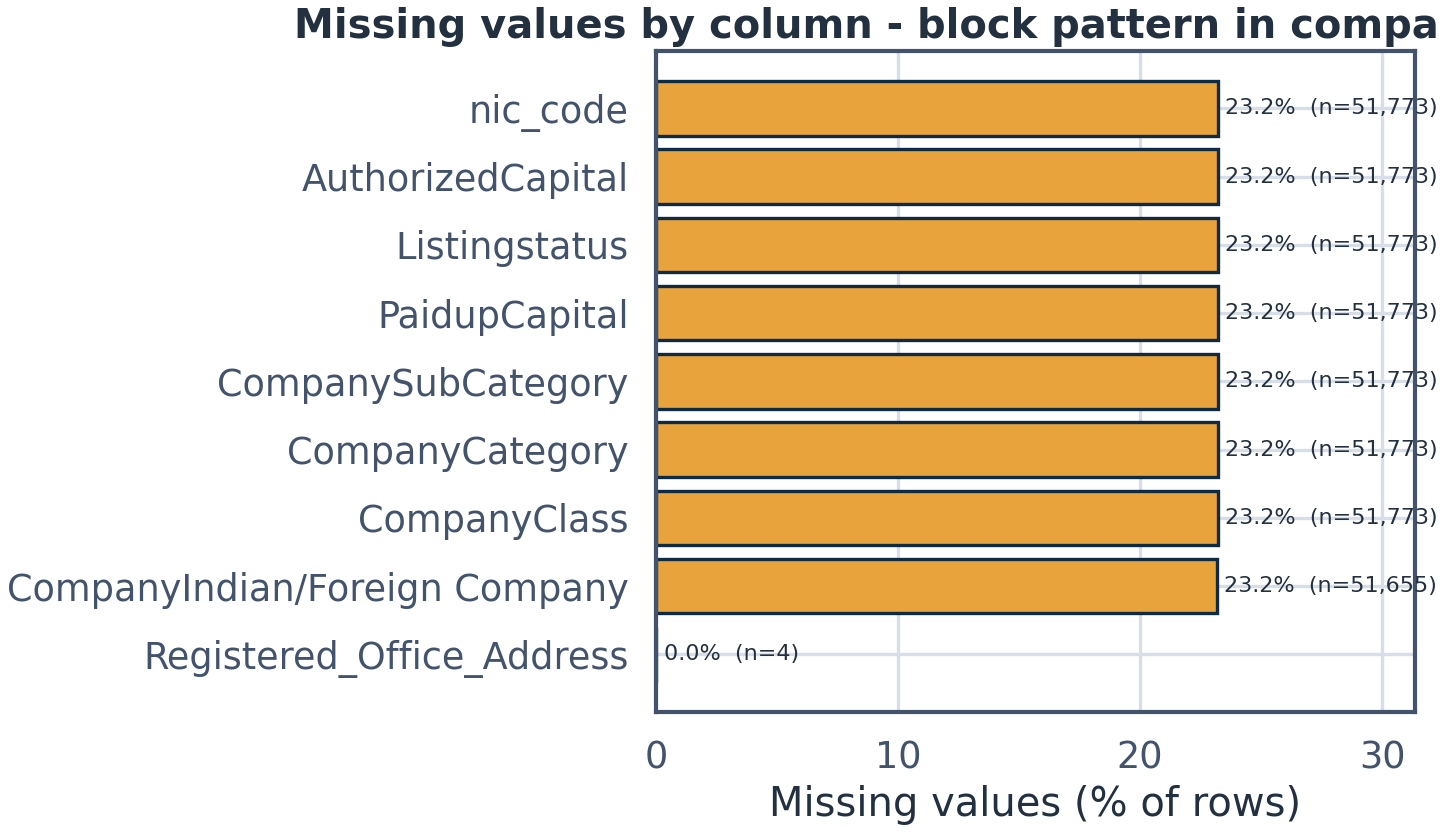

In [6]:
display(Image(filename=str(ROOT / "reports/figures/fig_missing_values.png")))

In [7]:
# (a) sentinel dates  (b) rule violation: paid-up > authorised  (c) country coded as 91
inv_dates = dc.find_invalid_dates(raw)
violations = dc.find_capital_violations(raw)
print("Invalid/sentinel registration dates:", len(inv_dates))
display(inv_dates.head(6))
print(f"\nPaid-up > Authorised violations: {len(violations)}  (impossible under Companies Act rules)")
display(violations.head(5))
print("\n'CompanyIndian/Foreign Company' top values (note the 39,392 rows coded '91'):")
raw["CompanyIndian/Foreign Company"].value_counts(dropna=False).head(8).to_frame()

Invalid/sentinel registration dates: 16


,CompanyRegistrationdate_date,issue
4310,1111-01-01,sentinel/unparsable date
10357,1111-11-11,sentinel/unparsable date
69435,1111-01-01,sentinel/unparsable date
78508,1111-01-01,sentinel/unparsable date
114508,1111-11-11,sentinel/unparsable date
146023,1111-01-01,sentinel/unparsable date



Paid-up > Authorised violations: 74  (impossible under Companies Act rules)


,CIN,CompanyName,AuthorizedCapital,PaidupCapital
1805,U92411GJ1991GAP016782,THE ABAD SPORTS CLUB LIMITED,0.000,"3,971,880.000"
3419,U17299GJ2021PTC123397,CONVICTION INDUSTRIES PRIVATE LIMITED,"500,000.000","550,000.000"
6898,U65910GJ1991PTC016680,SNEHBHAR STOCKHOLDINGS PVT. LTD.,"1,000,000.000","2,451,000.000"
7217,U74999GJ2020PTC114374,SANGAM MANAGEMENT SERVICES PRIVATE LIMITED,"10,000.000","100,000.000"
8192,U28920GJ1997PTC033257,SHRADDHA SYNTEX PRIVATE LIMITED,"100,000.000","2,059,000.000"



'CompanyIndian/Foreign Company' top values (note the 39,392 rows coded '91'):


,count
CompanyIndian/Foreign Company,
India,131749
NaN,51655
91,39392
Singapore,13
USA,12
United Kingdom,10
Germany,7
Japan,6


**Findings.** Identity keys are pristine (0 duplicate rows, 0 duplicate CINs), but content quality has real issues: **16** sentinel dates (`1111-01-01`), **74** paid-up > authorised impossibilities, **39,392** rows where the country is stored as the calling code `91`, plus cosmetic inconsistencies (`USA` vs `United States`). Each issue gets an explicit, logged treatment in the cleaning pipeline — nothing is silently dropped.

## 3 · Missing-data mechanism: MCAR, MAR or MNAR? (course module)
23.23% of rows miss **all** detail fields simultaneously (category, class, subcategory, capitals, listing, NIC). If missingness were MCAR it would be independent of every observed variable. We test that with chi-square associations against two observed variables — registration **era** and current **status**.

In [8]:
clean_probe = raw.copy()
clean_probe["block_missing"] = dc.detect_block_missing(clean_probe)
clean_probe["RegistrationYear"] = pd.to_datetime(
    clean_probe["CompanyRegistrationdate_date"], errors="coerce").dt.year
clean_probe["CompanyStatusGroup"] = dc.classify_status(clean_probe["CompanyStatus"])

mech = sa.missingness_mechanism_report(clean_probe)
print("Chi-square vs ERA:   ", mech["chi2_era"])
print("Chi-square vs STATUS:", mech["chi2_status"])
pd.DataFrame(mech["by_era"]).T.rename(columns={"pct_block_missing": "% block-missing", "n": "n"})

Chi-square vs ERA:    {'chi2': 32870.95, 'p_value': 0.0, 'dof': 4, 'cramers_v': 0.384, 'significant_5pct': True}
Chi-square vs STATUS: {'chi2': 10667.48, 'p_value': 0.0, 'dof': 4, 'cramers_v': 0.2188, 'significant_5pct': True}


,% block-missing,n
NaN,56.250,16.000
2016-2026,36.070,"134,727.000"
2011-2015,11.960,"24,699.000"
2001-2010,0.870,"24,724.000"
1991-2000,0.000,"24,462.000"
1850-1990,0.000,"14,287.000"


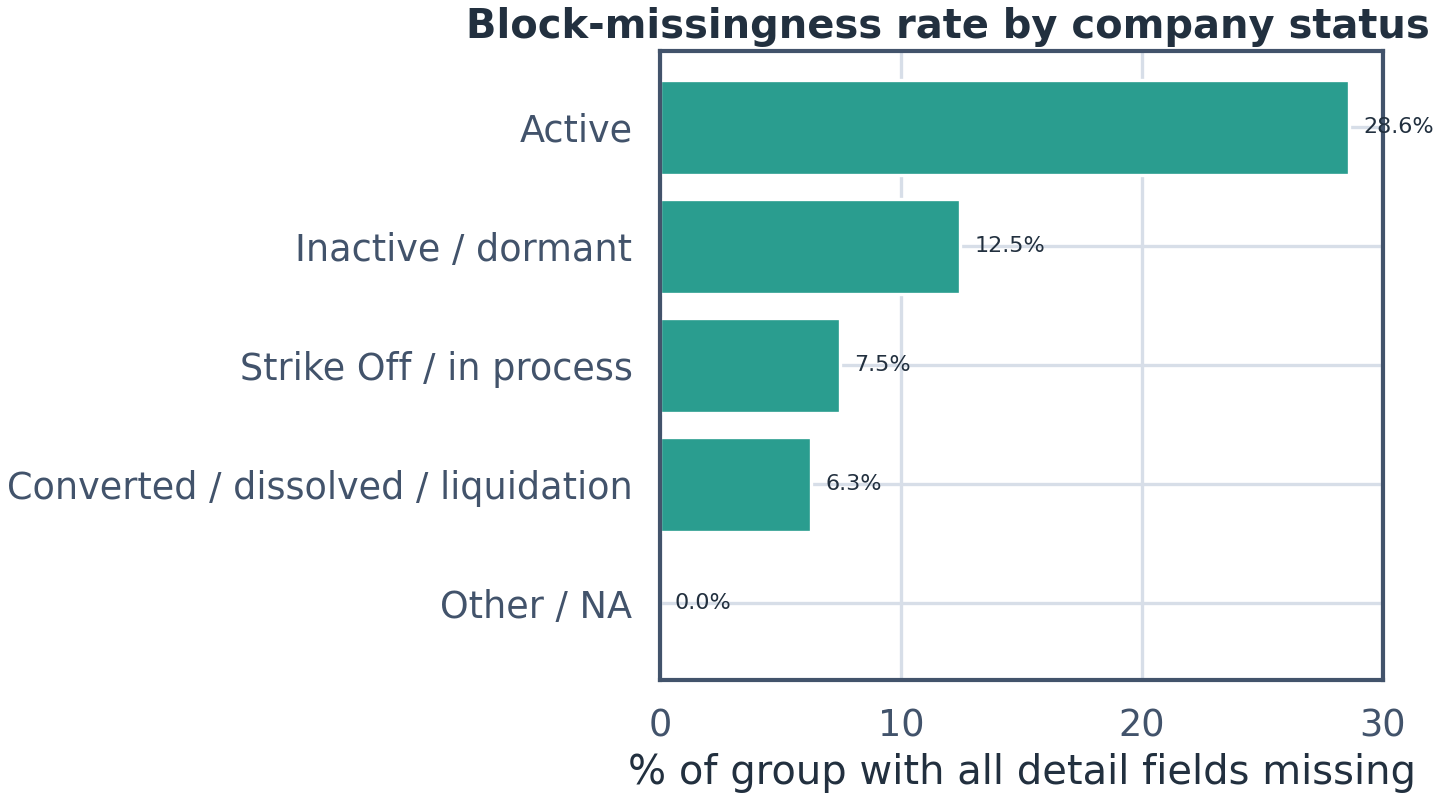

In [9]:
status_tbl = sa.missingness_by_group(clean_probe, "CompanyStatusGroup")
vz.plot_missingness_by_group(status_tbl)
display(Image(filename=str(ROOT / "reports/figures/fig_missingness_by_status.png")))

**Verdict — not MCAR.** Block-missingness hits **36.1%** of companies registered in 2016–2026 but is ~0% before 2001 (χ² = 32,871, p < 0.001, Cramér's V = 0.384), and **Active** companies miss details (28.6%) far more often than struck-off ones (7.5%). Missingness therefore *depends on observed variables* (→ MAR) with an administrative root cause (recent registrations whose detail fields were never populated in this MCA extract; → arguably MNAR w.r.t. company age). Practical consequence: **case-wise deletion would silently delete one-third of the newest cohort**, so we *flag* (`block_missing`) instead of dropping, and compute capital statistics only on the detail-known subset — reported transparently.

## 4 · Reproducible cleaning pipeline (CO1)
One function, one log. Every step records before/after evidence; the raw file stays untouched.

In [10]:
clean, clog = dc.clean_pipeline(raw,
                                drop_block_missing=False,  # keep & flag (see §3)
                                fix_country=True,
                                parse_dates=True,
                                drop_duplicates=True,
                                add_features=True)
import json
print(json.dumps(clog["steps"], indent=1))

[
 {
  "step": "deduplicate",
  "exact_duplicates_removed": 0,
  "duplicate_cin_removed": 0,
  "rows_after": 222915
 },
 {
  "step": "parse_dates",
  "sentinel_or_invalid_set_to_nat": 16
 },
 {
  "step": "standardize_country",
  "code_91_mapped_to_india": 39392
 },
 {
  "step": "flag_block_missing",
  "rows_flagged": 51773
 },
 {
  "step": "derive_features",
  "added": [
   "CompanyStatusGroup",
   "RegistrationYear",
   "RegistrationMonth",
   "IsListed",
   "IsForeign",
   "CapitalRatio",
   "CapitalViolation",
   "NICSection",
   "CapitalBucket"
  ]
 }
]


In [11]:
print("rows in / out:", clog["rows_in"], "/", clog["rows_out"],
      "| block-missing flagged:", clog["n_block_missing"])
known = clean.loc[~clean["block_missing"]].copy()   # analysis-ready subset (details known)
print(f"analysis-ready (details known): {len(known):,} rows")
clean.head(3).T

rows in / out: 222915 / 222915 | block-missing flagged: 51773
analysis-ready (details known): 171,142 rows


,0,1,2
CIN,U74999GJ1995PLC024124,U74999GJ1995PTC025084,U74999GJ1995PTC025739
CompanyName,PALCO RECYCLE EXCHANGE LIMITED,WESTERN INDIA SEA BRINES PVT LTD,FLACSEL CONTECH PRIVATE LIMITED
CompanyROCcode,ROC Ahmedabad,ROC Ahmedabad,ROC Ahmedabad
CompanyCategory,Company limited by shares,Company limited by shares,Company limited by shares
CompanySubCategory,Non-government company,Non-government company,Non-government company
CompanyClass,Public,Private,Private
AuthorizedCapital,"50,000,000.000","50,000,000.000","500,000.000"
PaidupCapital,"49,000,000.000","49,500,000.000","102,000.000"
CompanyRegistrationdate_date,1995-01-06 00:00:00,1995-03-21 00:00:00,1995-05-04 00:00:00
Registered_Office_Address,"RS No. 72, Opp. Super British Alloys Nr. Jalar...","OFFICE NO.7/1, 2ND FLOOR,, PLOT NO.32, SECTOR-...","5, BASEMENT, NIRMAL BUNGLOW NR. SUVIDHA SHOP..."


**New derived features** (feature engineering, course objective): `RegistrationYear/Month` (time series), `CompanyStatusGroup` (18 statuses → 4 groups), `IsListed`, `IsForeign` (after `91`→India normalisation), `CapitalRatio`, `CapitalViolation` flag, `NICSection` (5-digit NIC → 21 letter sections), `CapitalBucket` (₹-log bins), `block_missing` flag. The cleaned table is exported to `data/processed/company_master_cleaned.csv` by the pipeline script.

## 5 · Descriptive summary — centre, spread, shape (course module)
Raw capitals span ₹0 to ₹19,000,000,000,000, so we report both raw and **log10** summaries. With skewness ≈ 163–202 the mean is meaningless; the course's robust toolkit (median, IQR, MAD, five-number summary) is the right lens.

In [12]:
desc_auth = sa.descriptive_stats(known["AuthorizedCapital"])
desc_paid = sa.descriptive_stats(known["PaidupCapital"])
pd.DataFrame({"AuthorizedCapital": desc_auth, "PaidupCapital": desc_paid}).T[
    ["count", "mean", "median", "mode", "std", "iqr", "mad", "cv_pct", "skewness", "kurtosis", "min", "max"]]

,count,mean,median,mode,std,iqr,mad,cv_pct,skewness,kurtosis,min,max
AuthorizedCapital,171142,"111,647,081.700","100,000.000",[100000.0],"8,298,365,459.860","1,400,000.000","80,000.000","7,432.680",163.291,"30,807.467",0.000,"1,900,000,000,000.000"
PaidupCapital,171142,"58,892,976.281","100,000.000",[100000.0],"5,561,765,073.024","400,000.000","20,000.000","9,443.850",201.525,"46,516.694",0.000,"1,531,250,000,000.000"


In [13]:
print("Five-number summary (authorised capital, ₹):")
print(sa.five_number_summary(known["AuthorizedCapital"]))
print("\nlog10(authorised capital):")
pd.Series(sa.descriptive_stats(np.log10(known.loc[known['AuthorizedCapital'] > 0, 'AuthorizedCapital'])))[
    ["mean", "median", "std", "iqr", "mad", "skewness", "kurtosis"]].to_frame("log10 value")

Five-number summary (authorised capital, ₹):


{'min': 0.0, 'q1': 100000.0, 'median': 100000.0, 'q3': 1500000.0, 'max': 1900000000000.0, 'iqr': 1400000.0}

log10(authorised capital):


,log10 value
mean,5.670
median,5.000
std,0.949
iqr,1.176
mad,0.301
skewness,1.236
kurtosis,1.592


**Interpretation.** Median authorised capital = **₹1 lakh** vs mean = ₹11.2 crore — a 1,100× gap driven by mega-caps; CV ≈ 7,433%. On the log10 scale the distribution is *much* better behaved (skew 1.24, MAD ≈ 0.65 log-units). This motivates log transforms for every downstream visual and test.

## 6 · Univariate analysis (course module)
### 6.1 Categorical — class, status, listing, origin

In [14]:
class_dist = sa.categorical_distribution(known["CompanyClass"])
status_dist = sa.categorical_distribution(clean["CompanyStatusGroup"])
listing_dist = sa.categorical_distribution(clean["Listingstatus"])
origin_dist = sa.categorical_distribution(clean["CompanyIndian/Foreign Company"], top=8)
univ = pd.DataFrame({
    "CompanyClass": pd.Series({k: f"{v['count']:,} ({v['pct']}%)" for k, v in class_dist.items()}),
    "StatusGroup": pd.Series({k: f"{v['count']:,} ({v['pct']}%)" for k, v in status_dist.items()}),
    "Listing": pd.Series({k: f"{v['count']:,} ({v['pct']}%)" for k, v in listing_dist.items()}),
    "Origin": pd.Series({k: f"{v['count']:,} ({v['pct']}%)" for k, v in origin_dist.items()}),
}).fillna("")
univ

,CompanyClass,StatusGroup,Listing,Origin
Active,,"166,544 (74.71%)",,
Australia,,,,4 (0.0%)
Converted / dissolved / liquidation,,"6,381 (2.86%)",,
Germany,,,,7 (0.0%)
Inactive / dormant,,353 (0.16%),,
India,,,,"171,141 (99.93%)"
Japan,,,,6 (0.0%)
"Korea, South",,,,5 (0.0%)
Listed,,,"1,327 (0.78%)",
One Person Company,"3,332 (1.95%)",,,


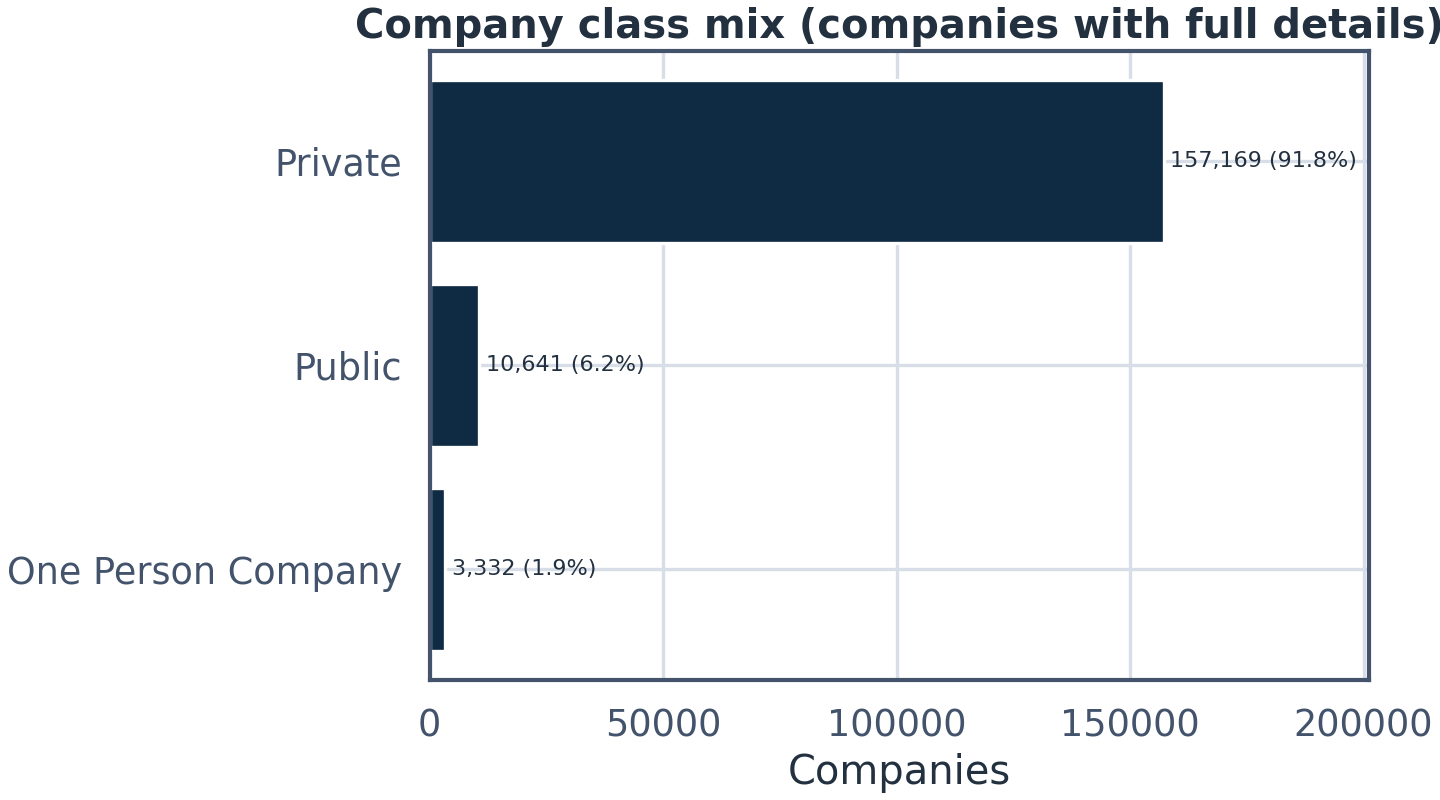

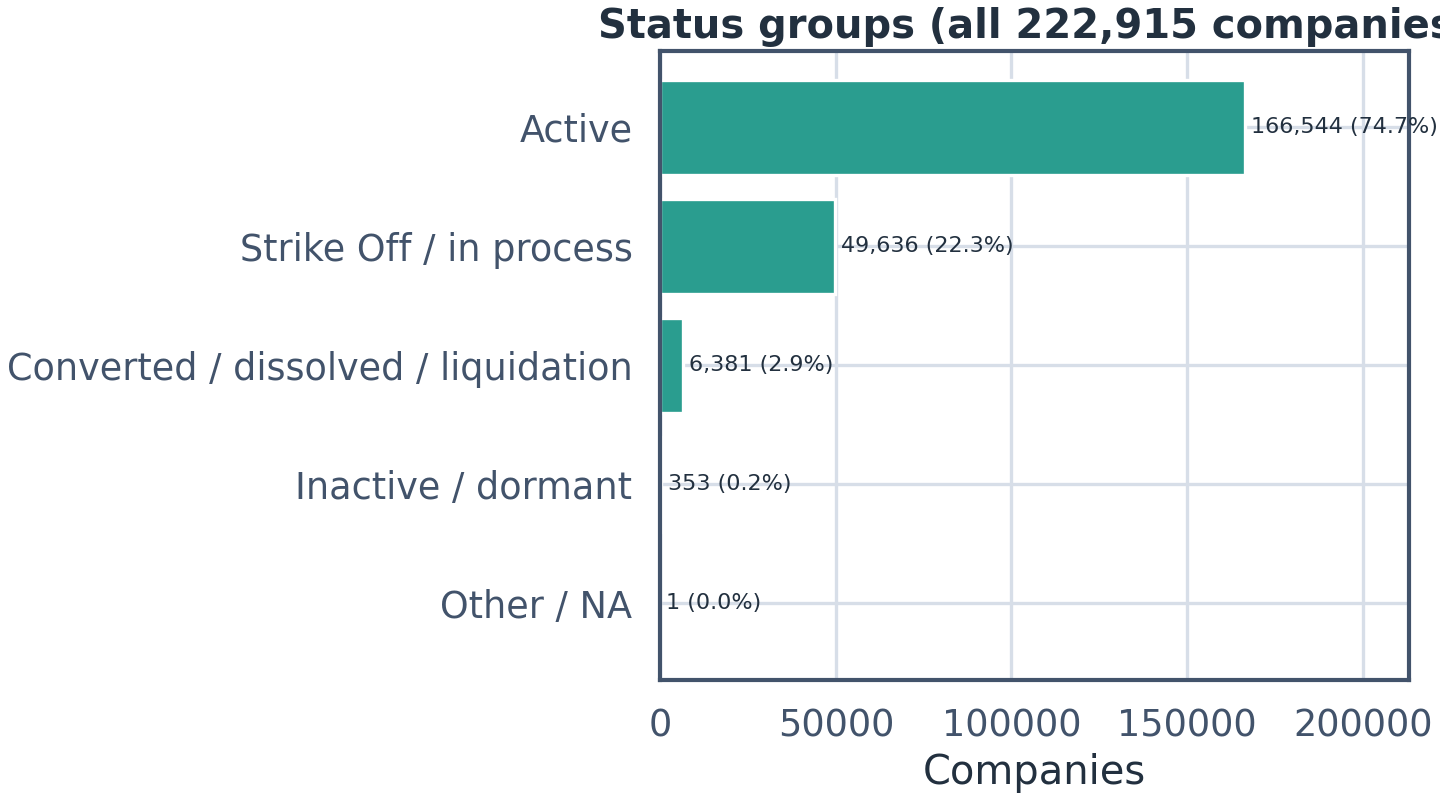

In [15]:
display(Image(filename=str(ROOT / "reports/figures/fig_class_distribution.png")))
display(Image(filename=str(ROOT / "reports/figures/fig_status_distribution.png")))

In [16]:
# Sector mix via NIC-2008 section mapping (nominal recode of nic_code)
sec = clean.loc[clean["NICSection"].notna(), "NICSection"].value_counts()
sec_df = pd.DataFrame({
    "section": sec.index,
    "label": [dc.NIC_SECTIONS.get(s, (None, None, s))[2] for s in sec.index],
    "companies": sec.values})
sec_df["pct"] = (sec_df["companies"] / sec_df["companies"].sum() * 100).round(2)
sec_df.head(10)

,section,label,companies,pct
0,C,Manufacturing,57769,34.910
1,M,Professional & scientific,29682,17.940
2,G,Wholesale & retail trade,17276,10.440
3,H,Transport & storage,14745,8.910
4,J,Information & communication,8207,4.960
5,K,Financial & insurance,7120,4.300
6,A,"Agriculture, forestry & fishing",4180,2.530
7,P,Education,3904,2.360
8,R,"Arts, entertainment & recreation",3716,2.250
9,N,Administrative & support,3512,2.120


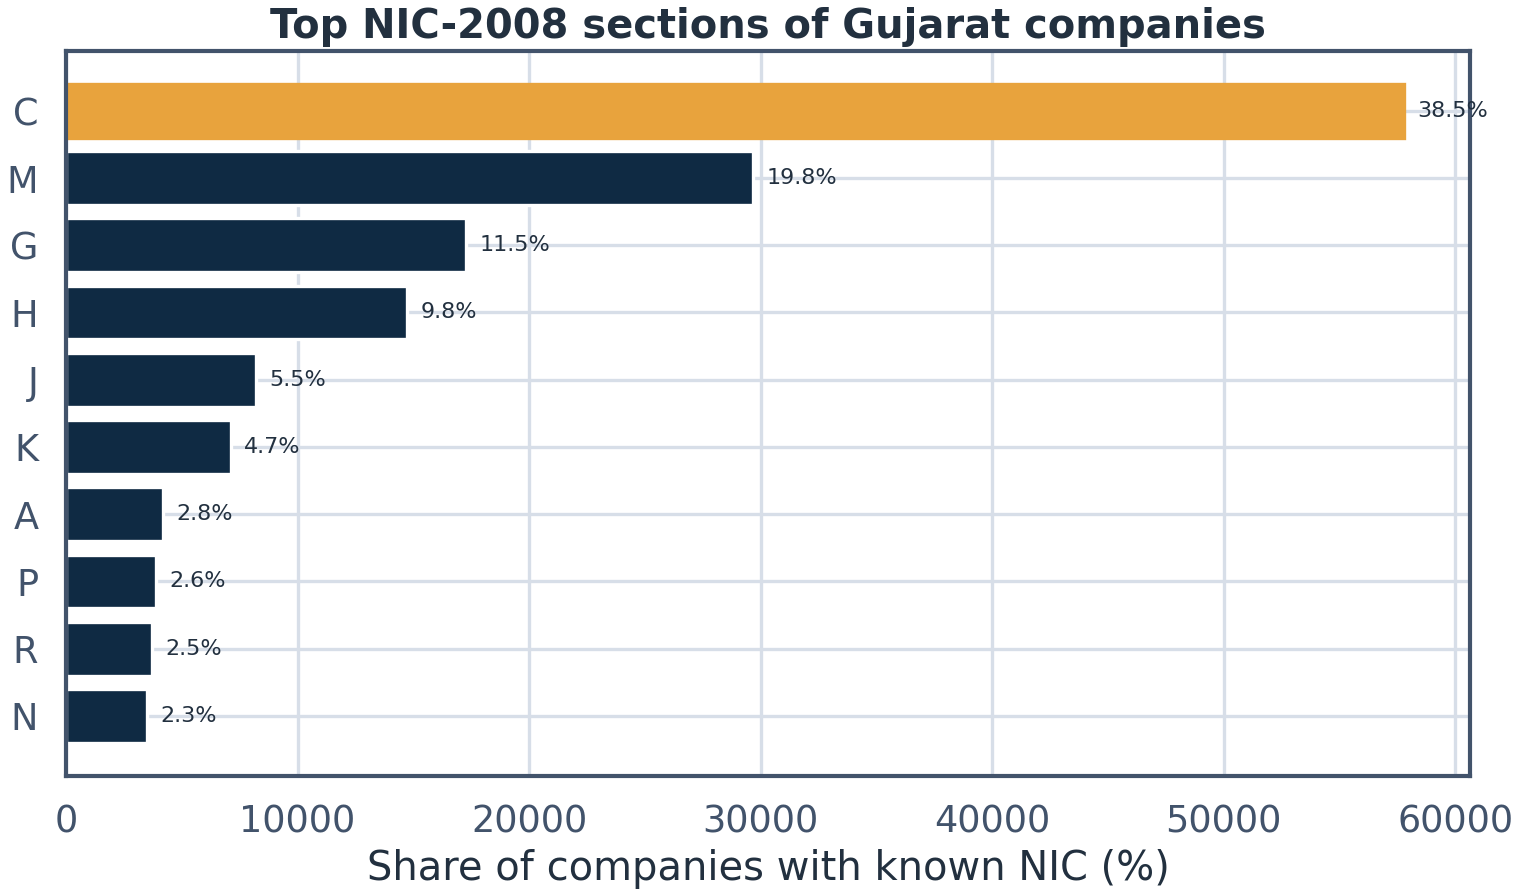

In [17]:
display(Image(filename=str(ROOT / "reports/figures/fig_nic_sections.png")))

### 6.2 Numeric — capital distributions (log scale)

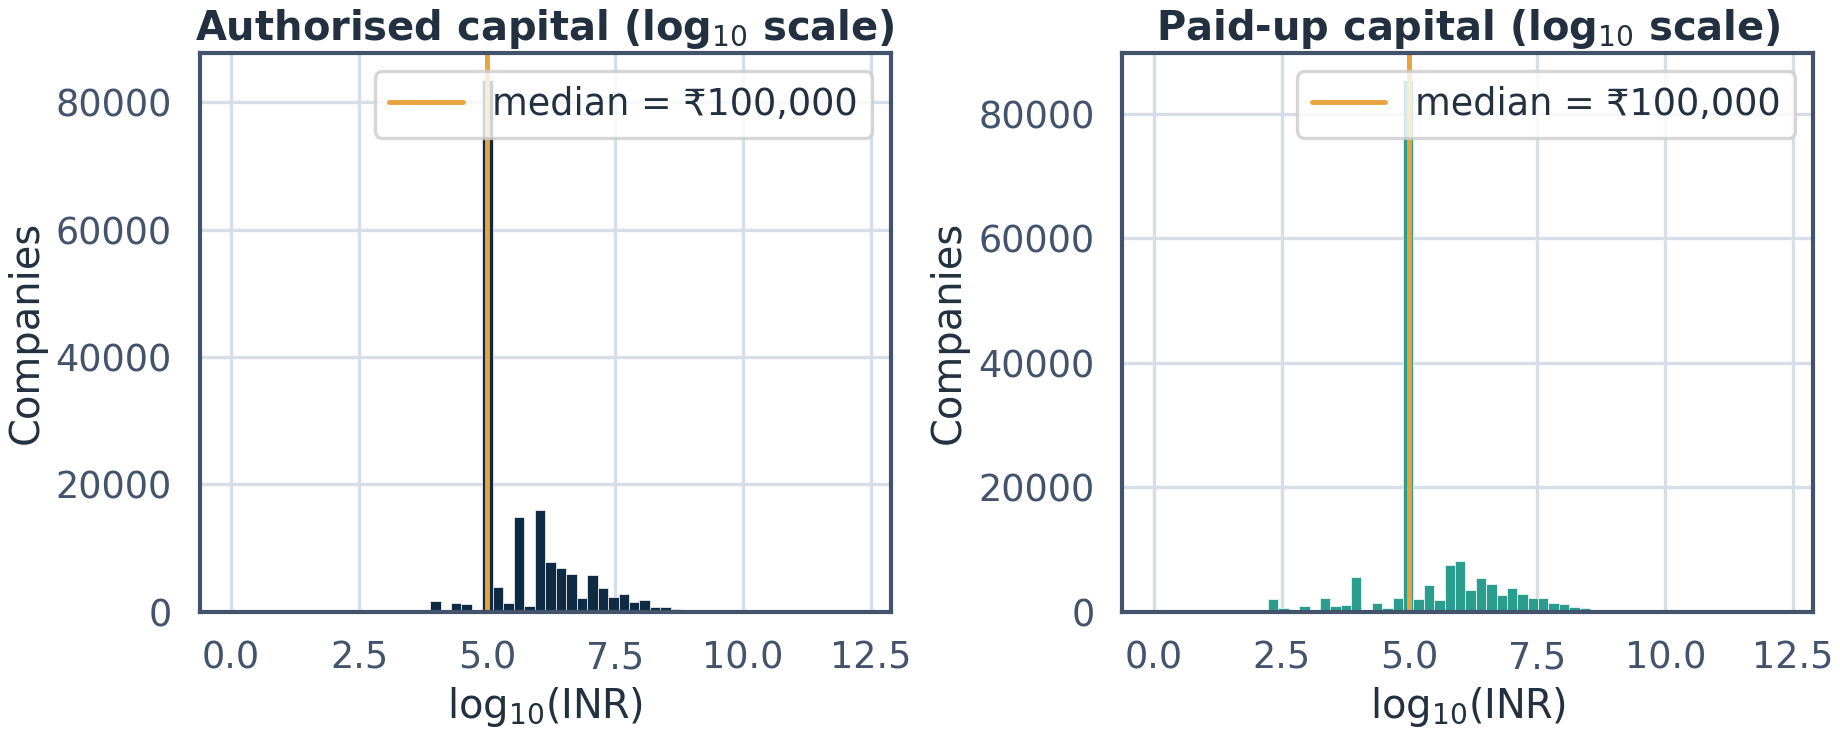

In [18]:
display(Image(filename=str(ROOT / "reports/figures/fig_capital_hist_log.png")))

**Read the histograms like an analyst.** Both capitals pile up at log₁₀ = 5 (**₹1 lakh — the minimum statutory / default figure**) and at round-number values, producing comb-like spikes. Authorised capital stretches to 10¹² while paid-up tops out at ~10¹²·² for one mega-company — the extreme right tail that breaks linear-scale plots.

## 7 · Outlier detection & concentration
Two course methods on log10 capital: Tukey's 1.5×IQR fences and z-scores (|z| > 3), then a look at *who* the outliers actually are.

In [19]:
out_iqr = sa.iqr_outliers(known["PaidupCapital"])
out_z = sa.zscore_outliers(known["PaidupCapital"])
print("IQR fences (log10 space):", {k: (f"₹{v:,.0f}" if k.endswith('fence') else v) for k, v in out_iqr.items()})
print("Z-score |z|>3:           ", out_z)

IQR fences (log10 space): {'lower_fence': '₹4,419', 'upper_fence': '₹18,101,934', 'n_outliers': 18050, 'pct_outliers': 11.27, 'space': 'log10'}
Z-score |z|>3:            {'threshold': 3.0, 'n_outliers': 1479, 'pct_outliers': 0.92, 'space': 'log10'}


In [20]:
top15 = known.nlargest(15, "PaidupCapital")[["CompanyName", "PaidupCapital", "CompanyClass", "CompanyStatusGroup"]]
top15["PaidupCapital"] = top15["PaidupCapital"].map(ins.inr)
top15

,CompanyName,PaidupCapital,CompanyClass,CompanyStatusGroup
158028,RELIANCE JIO INFOCOMM LIMITED,"₹153,125.00 Cr",Public,Active
148403,VODAFONE IDEA LIMITED,"₹108,343.04 Cr",Public,Active
155732,JIO DIGITAL FIBRE PRIVATE LIMITED,"₹78,655.92 Cr",Private,Active
186996,SARDAR SAROVAR NARMADA NIGAM LIMITED,"₹73,532.19 Cr",Public,Active
109576,GUJARAT URJA VIKAS NIGAM LIMITED,"₹45,589.65 Cr",Public,Active
172190,ARCELORMITTAL NIPPON STEEL INDIA PRIVATE LIMITED,"₹31,517.42 Cr",Private,Active
84685,ARCELORMITTAL INDIA PRIVATE LIMITED,"₹28,170.34 Cr",Private,Converted / dissolved / liquidation
104547,RELIANCE SERVICES AND HOLDINGS LIMITED,"₹26,953.69 Cr",Public,Active
140553,ONGC PETRO ADDITIONS LIMITED,"₹23,752.17 Cr",Public,Active
102678,SUZUKI MOTOR GUJARAT PRIVATE LIMITED,"₹12,841.11 Cr",Private,Converted / dissolved / liquidation


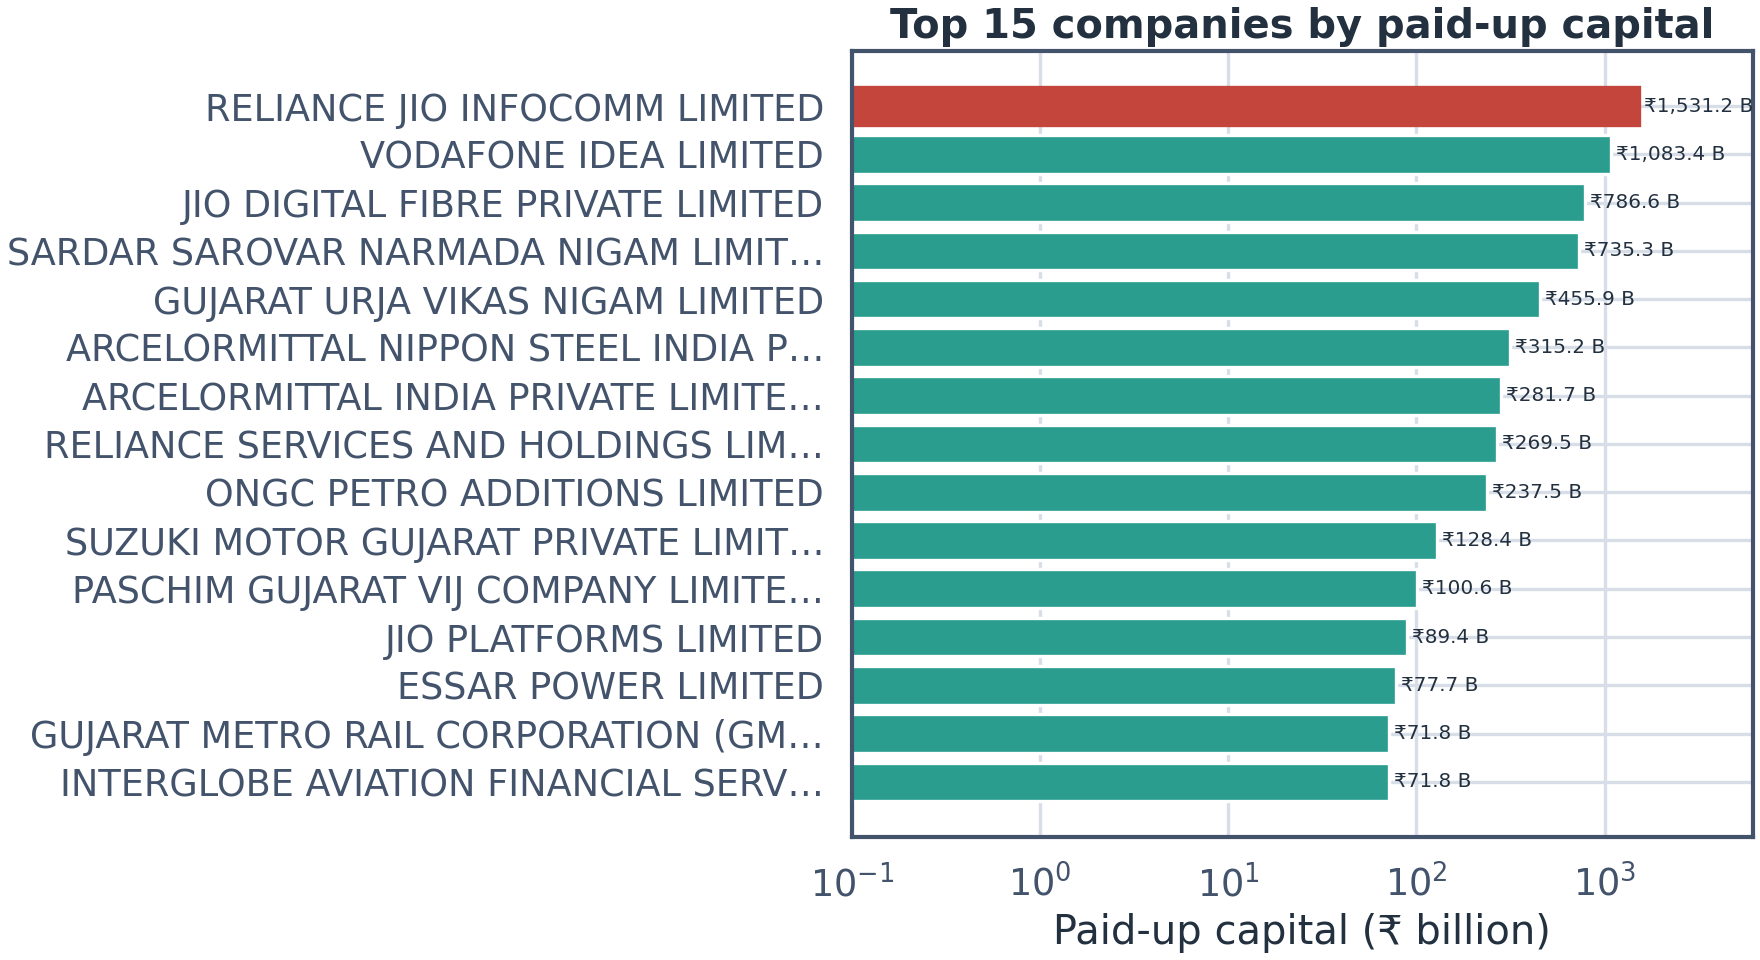

In [21]:
display(Image(filename=str(ROOT / "reports/figures/fig_top_paidup.png")))

Top 1% of companies hold 93.26% of all paid-up capital (Gini = 0.9918)
Top 5% hold 98.0%


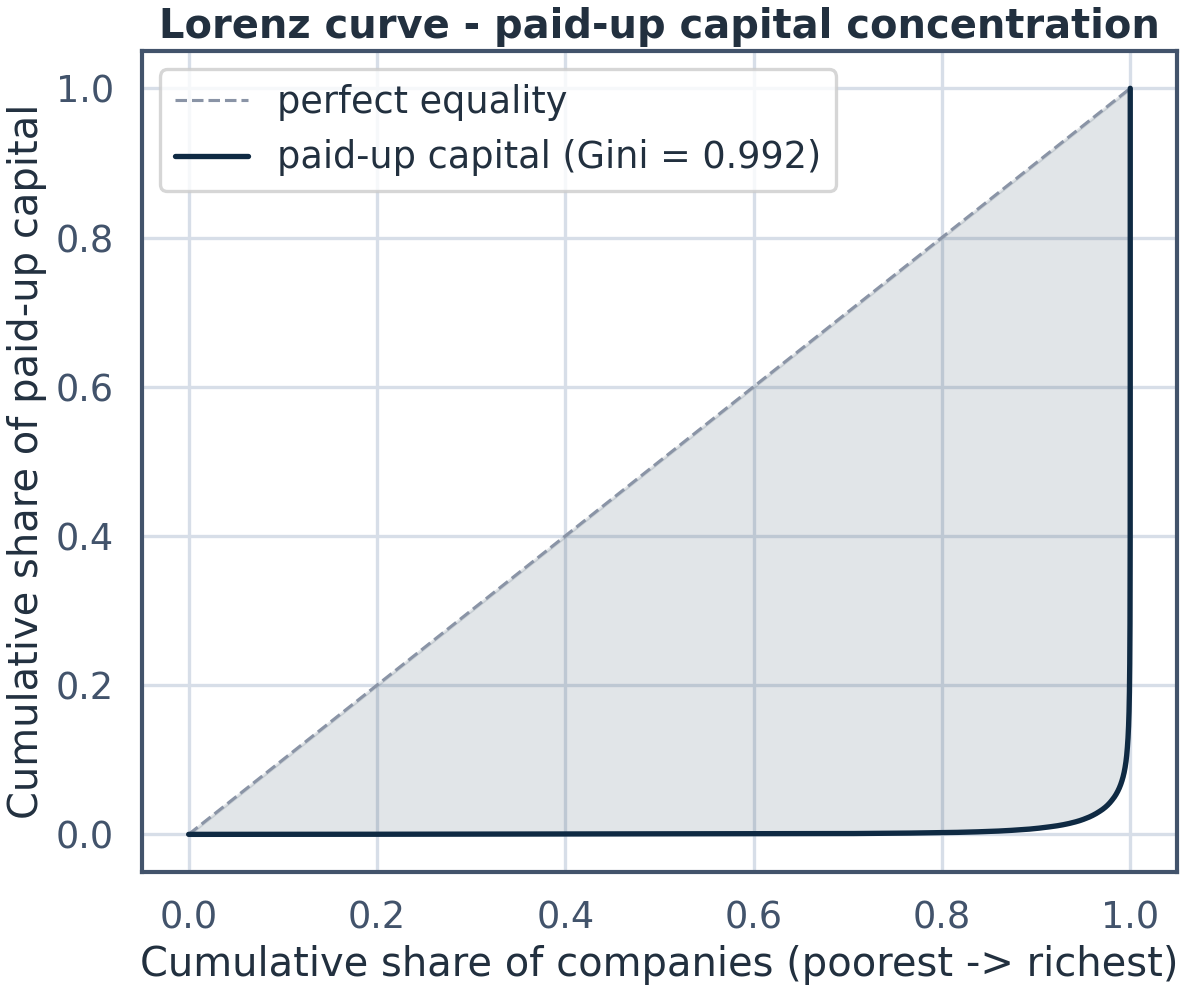

In [22]:
conc = sa.concentration_profile(known["PaidupCapital"], top_pct=1.0)
conc5 = sa.concentration_profile(known["PaidupCapital"], top_pct=5.0)
print(f"Top 1% of companies hold {conc['top_share_pct']}% of all paid-up capital (Gini = {conc['gini']})")
print(f"Top 5% hold {conc5['top_share_pct']}%")
display(Image(filename=str(ROOT / "reports/figures/fig_lorenz_capital.png")))

**Interpretation.** 11.3% of companies are IQR-outliers on the log scale — but they are *genuine* giants (Reliance Jio ₹1.53 lakh crore, Vodafone Idea, Jio Digital Fibre, Sardar Sarovar…), not data errors: they are kept and handled with robust statistics / log transforms. The Lorenz curve is nearly the diagonal-worst case: **Gini = 0.992, top 1% ≈ 93% of paid-up capital** — extreme capital concentration in a few corporate groups.

## 8 · Bivariate analysis (course module)
### 8.1 Class × status — crosstab + chi-square test of independence

In [23]:
ct = sa.crosstab_analysis(known, "CompanyClass", "CompanyStatusGroup", normalize=True)
display(ct["table"])
print(ct["chi2"])

CompanyStatusGroup,Active,Converted / dissolved / liquidation,Inactive / dormant,Other / NA,Strike Off / in process
CompanyClass,,,,,
One Person Company,2915,1,5,0,411
Private,109771,4899,209,1,42289
Public,6231,1080,95,0,3235


{'chi2': 2499.09, 'p_value': 0.0, 'dof': 8, 'cramers_v': 0.0854, 'significant_5pct': True}


In [24]:
ct["row_pct"]

CompanyStatusGroup,Active,Converted / dissolved / liquidation,Inactive / dormant,Other / NA,Strike Off / in process
CompanyClass,,,,,
One Person Company,87.480,0.030,0.150,0.000,12.330
Private,69.840,3.120,0.130,0.000,26.910
Public,58.560,10.150,0.890,0.000,30.400


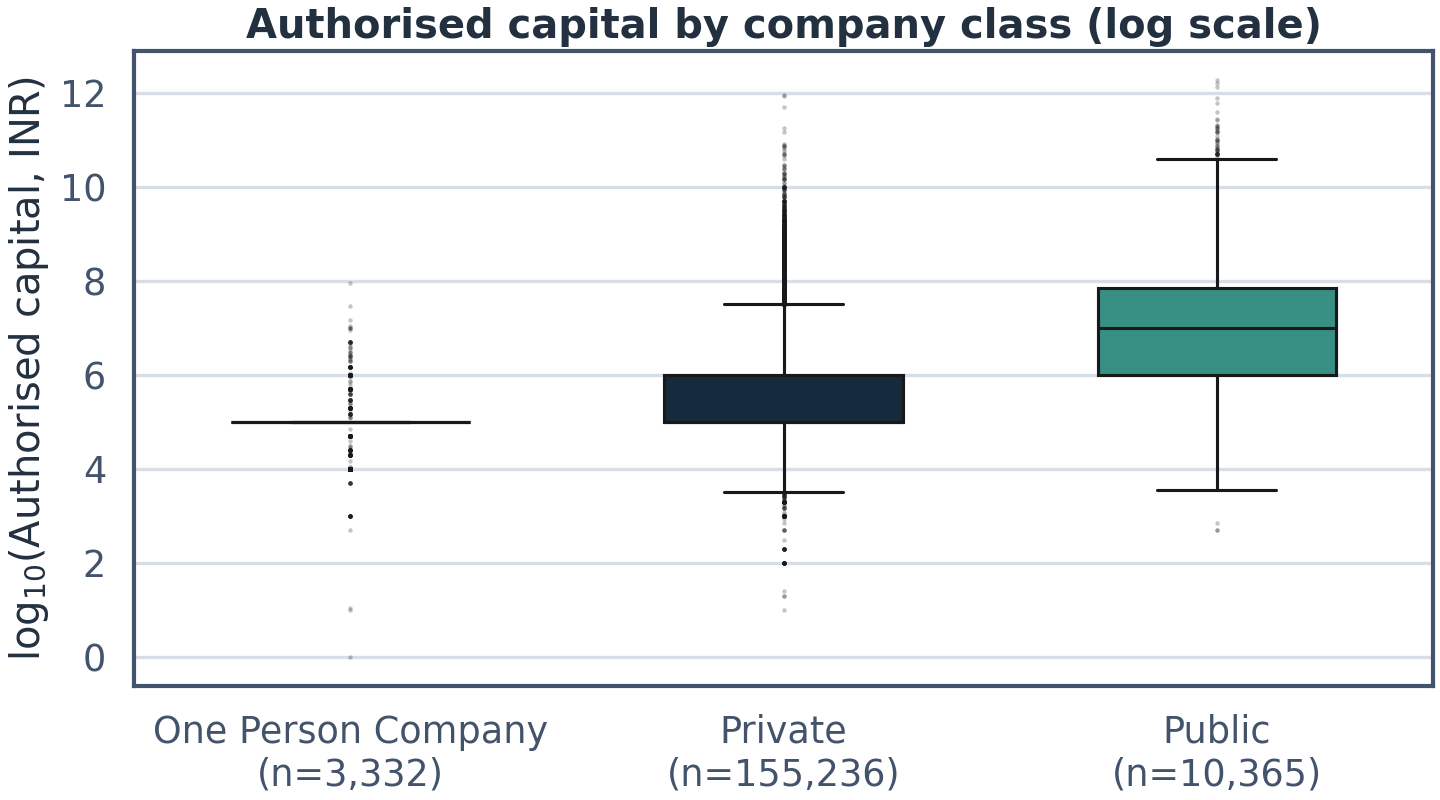

In [25]:
display(Image(filename=str(ROOT / "reports/figures/fig_capital_box_by_class.png")))

**Interpretation.** χ² = 2,499 (p < 0.001) — class and status are dependent; Cramér's V = 0.085 is modest (huge n makes even small effects significant). The pattern is intuitive: One Person Companies (post-2013 vehicles) are 87.5% active; public companies are the weakest cohort (58.6% active) with many defunct shells. Boxplots show private companies carry **lower** median authorised capital than public ones (public: many large infrastructure/utility firms).

## 9 · Correlation analysis & data fitting (course module)
Pearson + Spearman on **log10** capitals, then a simple OLS fit with goodness-of-fit statistics — the full "Correlation Analysis & Data fitting" toolkit.

Pearson (log10):  0.7697
Spearman:         0.765
n pairs used:     160198


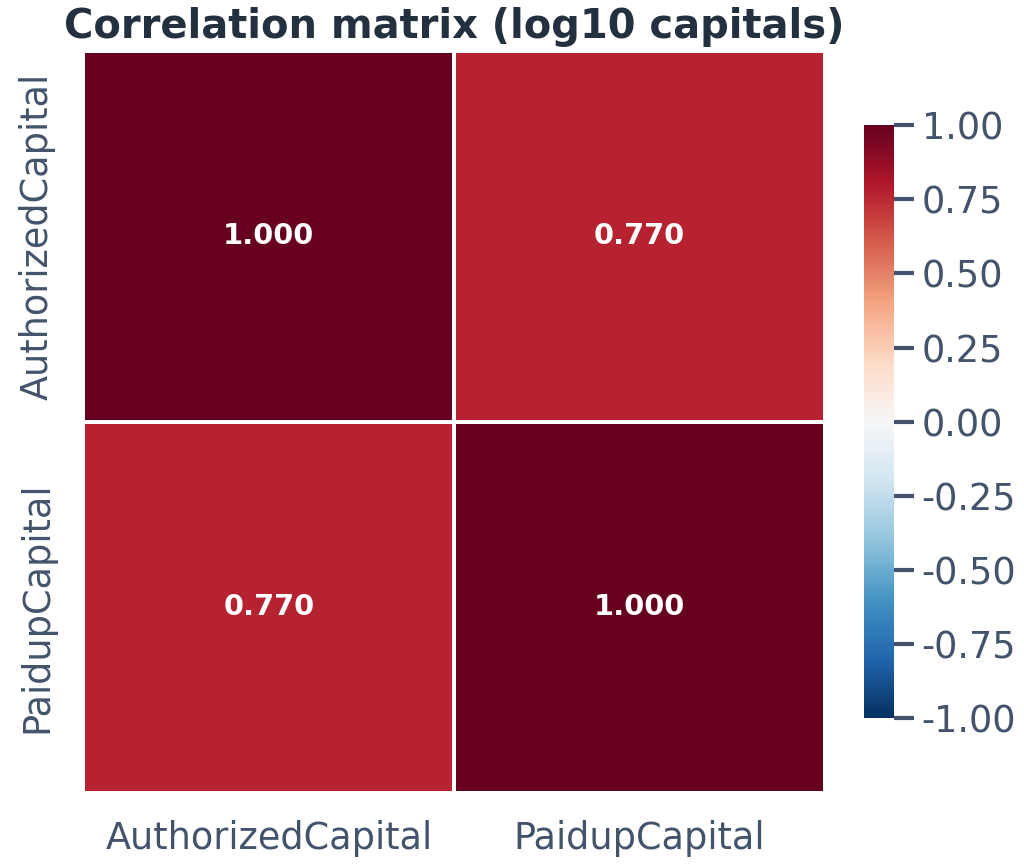

In [26]:
corr = sa.correlation_analysis(known, ["AuthorizedCapital", "PaidupCapital"], use_log=True)
print("Pearson (log10): ", corr["pearson"].iloc[0, 1])
print("Spearman:        ", corr["spearman"].iloc[0, 1])
print("n pairs used:    ", corr["n_used"])
display(Image(filename=str(ROOT / "reports/figures/fig_corr_heatmap.png")))

In [27]:
fit = sa.linear_fit(known["AuthorizedCapital"], known["PaidupCapital"], log10=True)
pd.Series(fit).to_frame("OLS log10 fit")

,OLS log10 fit
slope,0.874
intercept,0.388
r,0.770
r2,0.593
p_value,0.000
std_err,0.002
rmse_log10,0.696
n,160198
space,log10


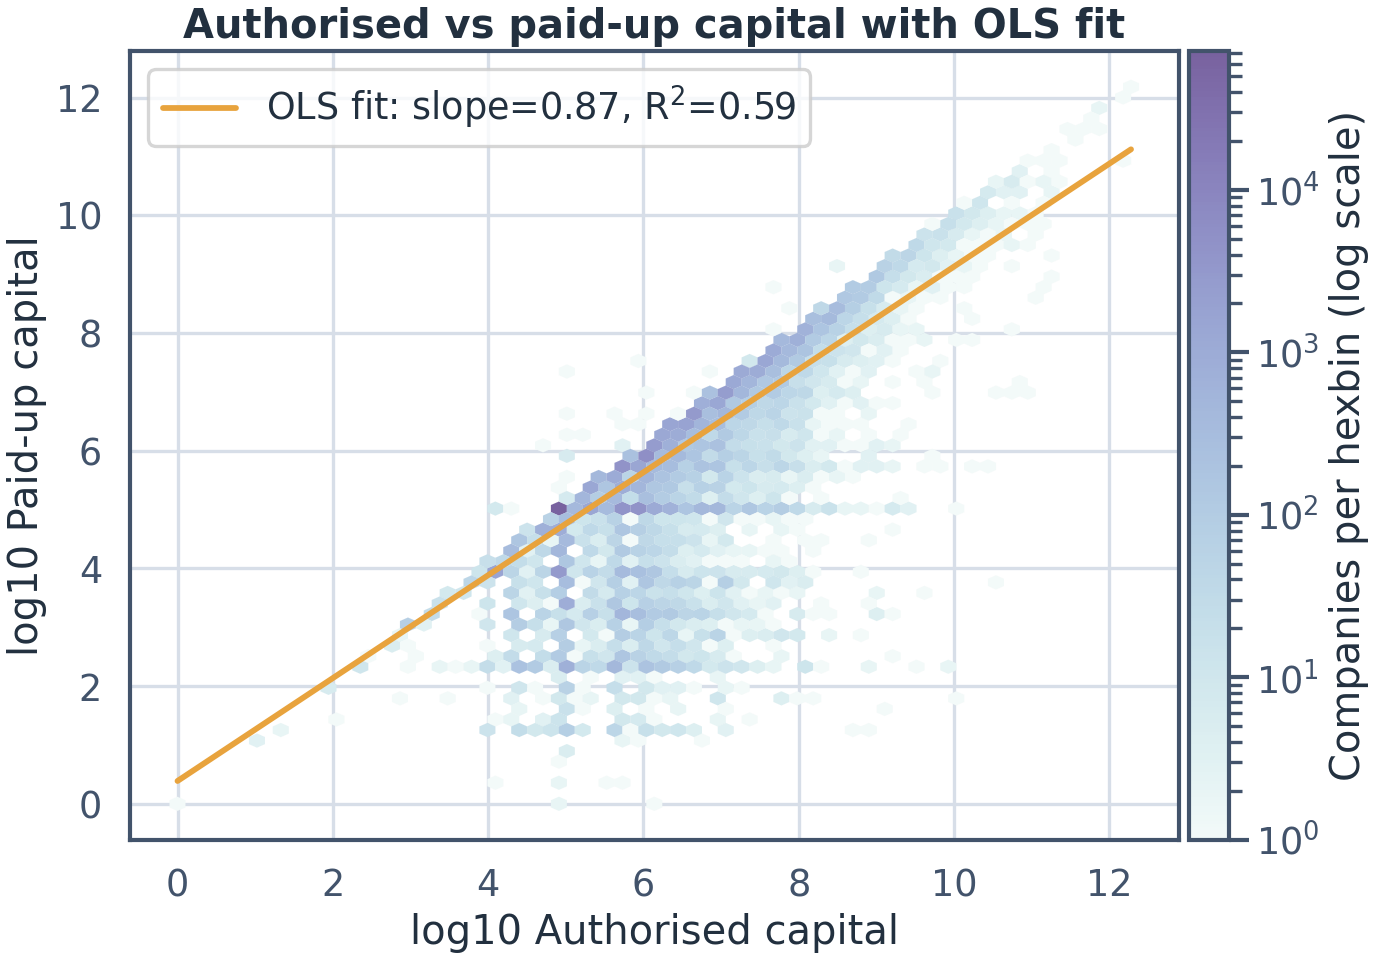

In [28]:
display(Image(filename=str(ROOT / "reports/figures/fig_capital_scatter_fit.png")))

**Interpretation.** Pearson r = 0.770 ≈ Spearman ρ = 0.765 — the monotone and linear pictures agree once log-transformed; no single outlier drives the association. The OLS slope **0.874** (SE 0.002): a 10× jump in authorised capital is associated with a ~7.5× rise in paid-up capital. R² = 0.59 leaves real dispersion — authorised capital is a *ceiling commitment*, not a guarantee of capitalisation. Note the horizontal stripe at 10⁵ (₹1-lakh default paid-up) visible in the hexbin.

## 10 · Time-series EDA — trend & seasonality (advanced EDA module)

{'peak_year': 2025, 'peak_n': 22407, 'cagr_end_year': 2025, 'cagr_2015_to_2025_pct': 15.59, 'decade_totals': {1880: 3, 1890: 2, 1900: 19, 1910: 18, 1920: 26, 1930: 52, 1940: 207, 1950: 161, 1960: 531, 1970: 1866, 1980: 9780, 1990: 24086, 2000: 22088, 2010: 60483, 2020: 103577}}


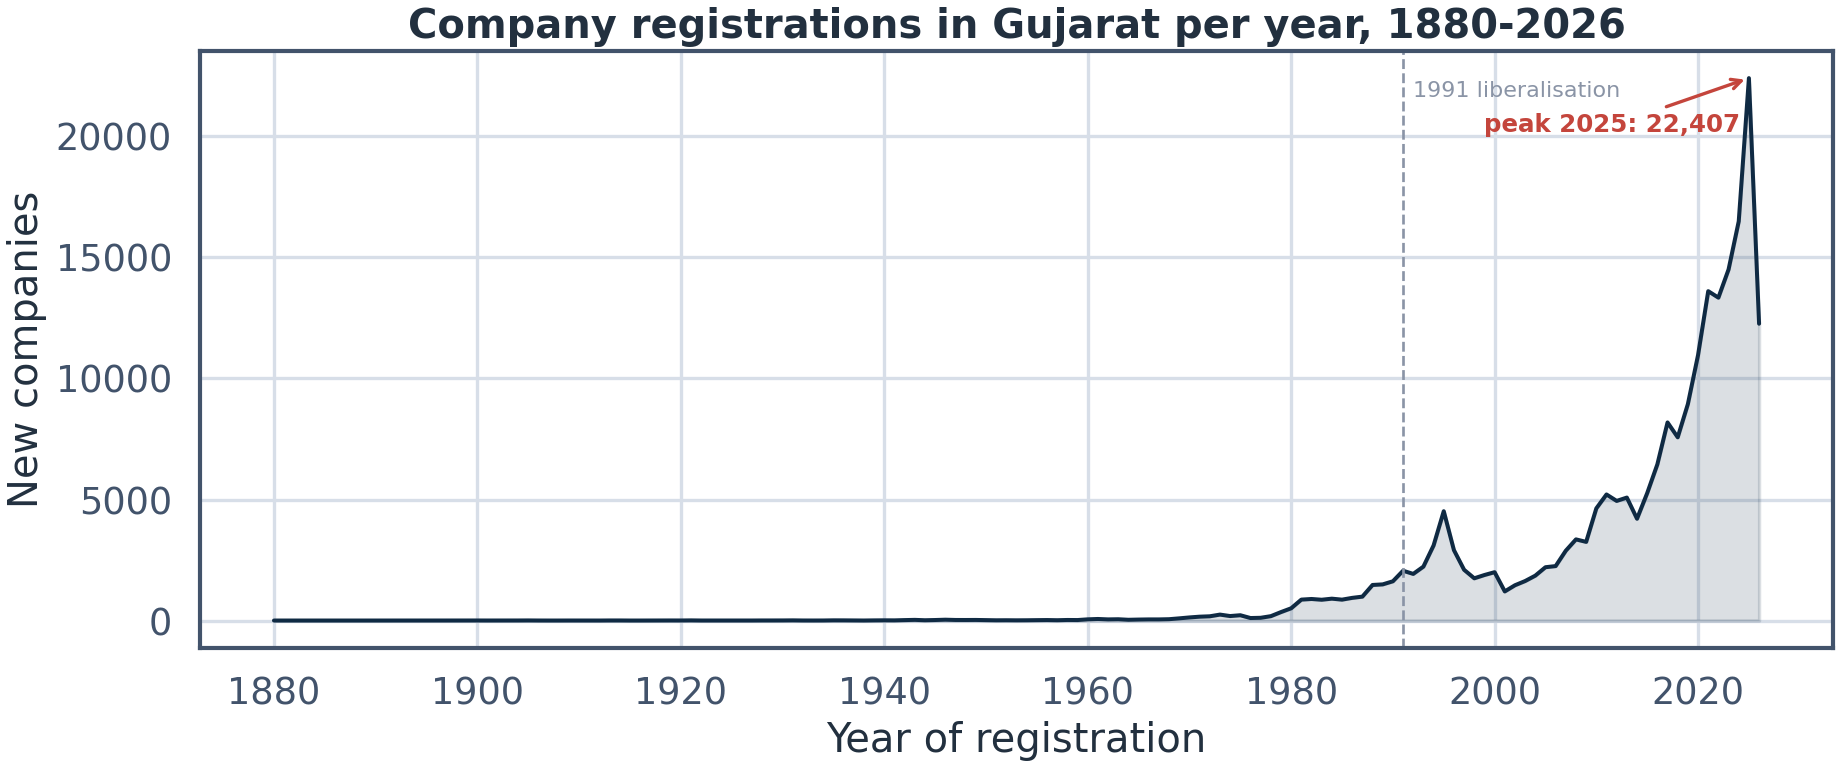

In [29]:
years = sa.yearly_registrations(clean)
months = sa.monthly_registrations(clean)
trend = sa.trend_summary(years, recent_from=2015, end_year=2025)  # 2026 partial (June snapshot)
print(trend)
display(Image(filename=str(ROOT / "reports/figures/fig_yearly_trend.png")))

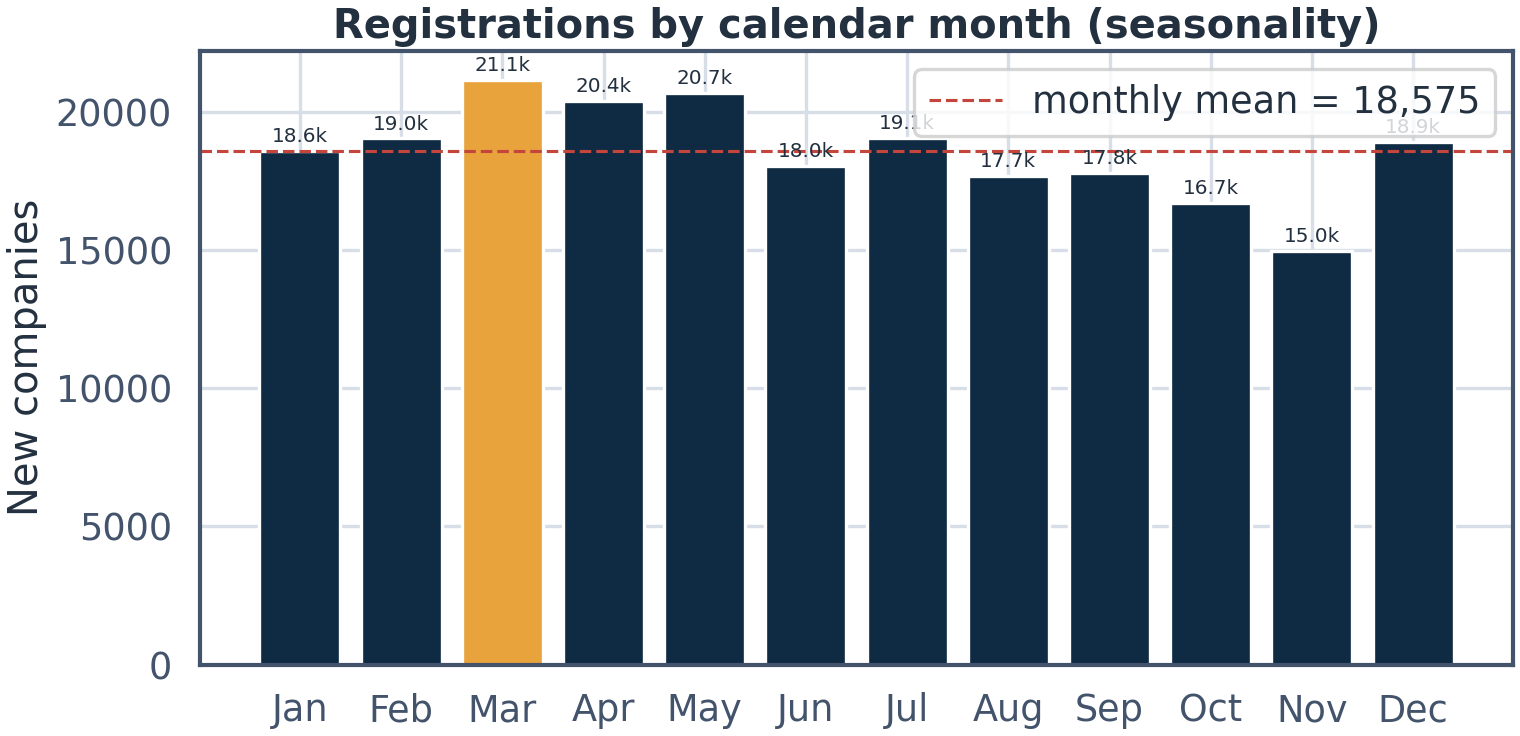

In [30]:
display(Image(filename=str(ROOT / "reports/figures/fig_month_seasonality.png")))

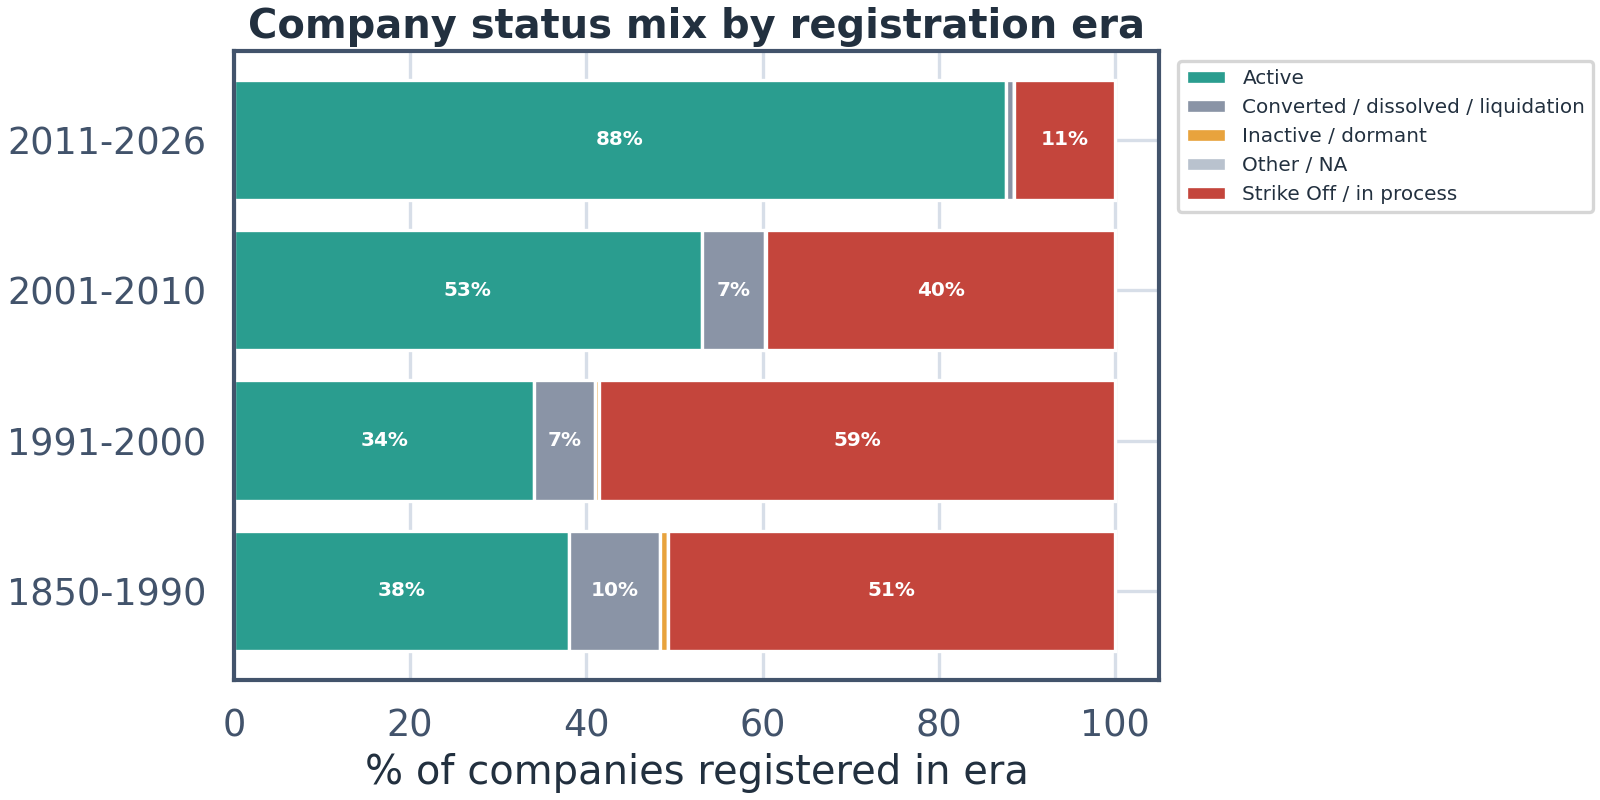

In [31]:
display(Image(filename=str(ROOT / "reports/figures/fig_status_by_era.png")))

**Interpretation.** Three regimes are visible: a pre-1991 trickle, a post-liberalisation lift (the 1994–97 mini-boom), and an explosive post-2020 phase — 5,263 registrations (2015) → **22,407 (2025)**, CAGR ≈ 15.6%; 2026 is already at 12,261 by June. Seasonality is real but moderate: **March** (financial year-end) peaks at 21.1k cumulative registrations, November troughs at 15.0k. The era chart doubles as a survivorship-bias warning: older cohorts show much higher strike-off/conversion shares — status mix is *not* comparable across eras without age adjustment.

## 11 · Key findings (auto-generated from the computed results)

In [32]:
for i, insight in enumerate(ins.build_insights({
        "overview": overview, "quality": quality,
        "missingness_mechanism": mech,
        "descriptives": {"AuthorizedCapital": desc_auth, "PaidupCapital": desc_paid},
        "concentration": conc, "correlation": {"pearson_r": corr["pearson"].iloc[0, 1],
                                               "spearman_r": corr["spearman"].iloc[0, 1]},
        "fit": fit, "crosstab_class_status": {"chi2": ct["chi2"]["chi2"],
                                              "p_value": ct["chi2"]["p_value"],
                                              "cramers_v": ct["chi2"]["cramers_v"]},
        "trend": trend, "trend_recent_base": years.get(2015, 0),
        "yearly_counts": {str(k): int(v) for k, v in years.items()},
        "monthly_counts": {str(k): int(v) for k, v in months.items()},
        "outliers_iqr": out_iqr,
        "sections_top": {r.section: {"count": int(r.companies), "label": r.label}
                         for r in sec_df.head(10).itertuples()},
        "n_nic_classified": int(clean["NICSection"].notna().sum()),
}), 1):
    display(Markdown(f"**{i}. {insight['title']}** — {insight['detail']}\n\n"
                     f"> Evidence: `{insight['evidence']}`"))

**1. A 146-year registry of Gujarat corporate India** — The file holds 222.9k companies registered with the Registrar of Companies, Ahmedabad, between 1880 and 2026 across 16 administrative fields. All records carry a state code of Gujarat, making this a single-state census of corporate registrations rather than a sample.

> Evidence: `rows=222915; cols=16; years=1880-2026; state=gujarat (100%)`

**2. Identity keys are pristine - no duplicates at all** — Despite 222.9k records there are 0 duplicate rows and 0 repeated CINs, so every company appears exactly once. Cleaning effort can therefore focus on content issues rather than identity resolution.

> Evidence: `duplicate_rows=0; duplicate_CIN=0`

**3. 23.23% of rows miss ALL detail fields together - and the pattern is NOT random** — 51.8k rows lack every company-detail field (category, class, subcategory, capitals, listing status, NIC code) simultaneously, while identifier fields are 100% populated. Block-missingness is strongly associated with observed variables: it reaches 36.1% for companies registered in 2016-2026 but is ~0% before 2001 (chi2 era: p < 0.001, Cramer's V = 0.384), and Active companies miss more (28.6%) than struck-off ones (7.5%) (V = 0.2188). The mechanism is therefore MAR/MNAR with an administrative cause - recent registrations in the extract simply have not had their detail fields populated - rather than pure MCAR.

> Evidence: `block_missing=51773 (23.23%); chi2_era V=0.384; chi2_status V=0.2188; 2016-2026 rate=36.07%; pre-2001 rate=~0%`

**4. Corporate capital is extremely right-skewed** — Authorised capital has a median of ₹1.00 L against a mean of ₹11.16 Cr (skewness 163.291), with values from ₹0 to ₹190,000.00 Cr. The coefficient of variation exceeds 7,000%, so all capital analysis uses log10 scale and robust statistics (median, IQR, MAD) per the course's descriptive-summary module.

> Evidence: `median=100000.0; mean=111647081.70004377; skew=163.291; cv%=7432.68`

**5. The top 1.0% of companies hold 93.26% of paid-up capital** — The Lorenz curve shows extreme inequality (Gini = 0.9918): a handful of mega-companies dominate Gujarat's corporate capital, while the median company is capitalised at just ₹1.00 L. This mirrors the national picture where a few large listed groups hold most subscribed capital.

> Evidence: `top_share=93.26%; gini=0.9918; n=160.2k`

**6. Authorised and paid-up capital move together (R2 = 0.5925)** — On the log10 scale, paid-up capital rises almost proportionally with authorised capital: Pearson r = 0.7697 (Spearman rho = 0.765, robust to heavy tails). The OLS slope of 0.8743 implies that a 10x increase in authorised capital is associated with roughly a 10^0.87 = ~7.5x increase in paid-up capital - authorisation tracks, but does not guarantee, actual capitalisation.

> Evidence: `pearson=0.7697; spearman=0.765; slope=0.8743; r2=0.5925; n=160.2k`

**7. Company class and legal status are significantly dependent** — A chi-square test of the class x status crosstab gives chi2 = 2,499 (p < 0.001); Cramer's V = 0.0854 indicates a modest but reliable association given the huge sample. One Person Companies are the healthiest cohort (87.5% active, only 12.3% struck off), whereas public companies show the weakest active share (58.6% active, 30.4% struck off / in process) - consistent with many old public companies being defunct shells.

> Evidence: `chi2=2499.09; p=0.0; cramers_v=0.0854; OPC active=87.5%; Public active=58.6%`

**8. Registrations exploded to a peak of 22.4k in 2025** — Annual registrations grew from 5.3k in 2015 to 22.4k in 2025 (CAGR 2025%, 2015-2025), with every year since 2021 exceeding 13,000. The post-2020 acceleration is consistent with SPICe+ online incorporation and start-up formalisation; 2026 is already at 12.3k registrations by June, on pace for another record. March dominates the calendar pattern (financial year-end rush) while November is the quietest month, confirming seasonality.

> Evidence: `peak=2025 (22.4k); cagr2015-2025=2025%; march=21134 vs nov=14972`

**9. 18050 capital outliers on the log scale - and they are real giants** — Tukey's 1.5*IQR fences on log10 capital flag 11.27% of companies as high-side outliers, led by mega-cap names whose paid-up capital reaches ₹153,125.00 Cr. Zero-capital entries (10.9k companies with ₹0 paid-up) form the low-side special case requiring separate treatment.

> Evidence: `iqr_outliers=18050 (11.27%); max_paidup=1531250000000.0; zero_paidup=10925`

**10. Manufacturing leads with 34.9% of classified companies** — Among the 165.5k companies with a known NIC code, the top sectors are Manufacturing (57,769), Professional & scientific (29,682) and Wholesale & retail trade (17,276) - a signature of Gujarat's industry-and-entrepreneurship-led economy. The 5-digit NIC codes also demonstrate a clean nominal-scale mapping to the 21 one-letter NIC-2008 sections used for grouped analysis.

> Evidence: `top=Manufacturing (57769), Professional & scientific (29682), Wholesale & retail trade (17276); classified_total=165485`

## 12 · Limitations & conclusions
### Limitations (stated honestly)
1. **Registry, not economy.** The file counts *registered* companies; no turnover/employment data — capital is a commitment, not activity.
2. **Detail fields missing for 23.2%** of rows (block pattern, §3): capital statistics describe the 171,142 detail-known companies and exclude ~36% of the newest cohort — a documented selection effect.
3. **Snapshot censoring.** The extract stops in June 2026; 2026 counts are partial and excluded from CAGR.
4. **Status ≠ survival time.** We observe current status only, not closure dates, so "survival" claims stay descriptive.
5. **Zero-capital entries** (10,925 with ₹0 paid-up) and 74 rule violations remain flagged rather than "fixed" — we refuse to invent corrections.

### Conclusions
- The dataset is a **clean census of Gujarat's corporate registry** (0 duplicates) whose real analytical weight sits in content quality: block missingness (MAR/MNAR), sentinel dates and coded-country labels — exactly the issues the IT462 cleaning module trains for.
- Gujarat's corporate landscape is **private-dominated (91.8%)**, **extremely concentrated** (top 1% ≈ 93% of paid-up capital, Gini 0.992) and **manufacturing-led (38.5% of classified companies)**.
- Authorised and paid-up capital are **strongly associated on the log scale** (r ≈ 0.77, R² ≈ 0.59, slope 0.87), with ₹1-lakh statutory defaults shaping both distributions.
- Registrations follow a **structural upward trend** (peak 22.4k in 2025; CAGR 15.6% since 2015) with a **March seasonality** — a dashboard-ready story, delivered interactively in `website/app.py`.

### Next steps
Model churn/strike-off probability (logistic) · time-to-strike-off survival analysis · join with financial filings (MCA XBRL) for activity-based analysis · geocode registered offices for district-level dashboards.

In [33]:
# Export check: what the pipeline persisted for the other deliverables
for p in ["data/processed/company_master_cleaned.csv", "data/processed/analysis_results.json"]:
    f = ROOT / p
    print(f"{p}: {f.stat().st_size/1e6:.1f} MB")
print("\nFigures available in reports/figures/:")
for f in sorted((ROOT / "reports/figures").glob("*.png")):
    print("  ", f.name)

data/processed/company_master_cleaned.csv: 80.2 MB
data/processed/analysis_results.json: 0.1 MB

Figures available in reports/figures/:
   fig_capital_box_by_class.png
   fig_capital_hist_log.png
   fig_capital_scatter_fit.png
   fig_class_distribution.png
   fig_corr_heatmap.png
   fig_lorenz_capital.png
   fig_missing_values.png
   fig_missingness_by_status.png
   fig_month_seasonality.png
   fig_nic_sections.png
   fig_status_by_era.png
   fig_status_distribution.png
   fig_top_paidup.png
   fig_yearly_trend.png
